<a href="https://colab.research.google.com/github/shubhranshu-bit/AIML-research-papers/blob/main/Ensemble_Stacking_LLG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

# Mount Google Drive
drive.mount('/content/drive')


from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/Fault_dataset'

Mounted at /content/drive
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import pandas as pd
path='/content/drive/MyDrive/Fault_dataset/BCG modified.csv'
df = pd.read_csv(path)
df

,Time,Absolute Ia,Absolute Ib,Absolute Ic,Fault
0,0.000000,0.008215,0.192289,0.164458,0
1,0.000167,0.014444,0.194102,0.161226,0
2,0.000333,0.020655,0.195216,0.157385,0
3,0.000500,0.026836,0.195626,0.152939,0
4,0.000667,0.032972,0.195325,0.147891,0
...,...,...,...,...,...
5995,0.999127,0.024975,0.148062,0.148901,0
5996,0.999293,0.020432,0.152660,0.149676,0
5997,0.999460,0.015841,0.156692,0.149932,0
5998,0.999627,0.011209,0.160152,0.149665,0


In [ ]:
y = df['Fault']
y

0       0
1       0
2       0
3       0
4       0
       ..
5995    0
5996    0
5997    0
5998    0
5999    0
Name: Fault, Length: 6000, dtype: int64

In [ ]:
X = df.drop(['Time', 'Fault'], axis=1)
X

,Absolute Ia,Absolute Ib,Absolute Ic
0,0.008215,0.192289,0.164458
1,0.014444,0.194102,0.161226
2,0.020655,0.195216,0.157385
3,0.026836,0.195626,0.152939
4,0.032972,0.195325,0.147891
...,...,...,...
5995,0.024975,0.148062,0.148901
5996,0.020432,0.152660,0.149676
5997,0.015841,0.156692,0.149932
5998,0.011209,0.160152,0.149665


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, precision_score


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
dt_classifier = DecisionTreeClassifier(max_depth=5,random_state=42)
nb_classifier = GaussianNB()
svm_classifier = SVC(kernel='linear', random_state=42)
mlp_classifier = MLPClassifier(alpha=1, max_iter=1000)
rf_classifier = RandomForestClassifier(n_estimators=100, random_state=42)


dt_classifier.fit(X_train, y_train)
nb_classifier.fit(X_train, y_train)
svm_classifier.fit(X_train, y_train)
mlp_classifier.fit(X_train, y_train)
rf_classifier.fit(X_train, y_train)

dt_pred = dt_classifier.predict(X_test)
nb_pred = nb_classifier.predict(X_test)
svm_pred = svm_classifier.predict(X_test)
mlp_pred = mlp_classifier.predict(X_test)
rf_pred = rf_classifier.predict(X_test)

# Calculate individual accuracies

dt_accuracy = accuracy_score(y_test, dt_pred)
nb_accuracy = accuracy_score(y_test, nb_pred)
svm_accuracy = accuracy_score(y_test, svm_pred)
mlp_accuracy = accuracy_score(y_test, mlp_pred)
rf_accuracy = accuracy_score(y_test, rf_pred)

print("Decision Tree Accuracy:", dt_accuracy)
print("Naive Bayes Accuracy:", nb_accuracy)
print("SVM Accuracy:", svm_accuracy)
print("MLP Accuracy:", mlp_accuracy)
print("Random Forest Accuracy:", rf_accuracy)

Decision Tree Accuracy: 0.9633333333333334
Naive Bayes Accuracy: 0.9533333333333334
SVM Accuracy: 0.93
MLP Accuracy: 0.9291666666666667
Random Forest Accuracy: 0.975


In [ ]:
from sklearn.ensemble import StackingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, f1_score

# Initialize base classifiers
base_estimators = [
    ('rf', RandomForestClassifier(n_estimators=100, random_state=42)),
    ('dt', DecisionTreeClassifier(random_state=42)),
    ('nb', GaussianNB()),
    ('svm', SVC(kernel='linear', probability=True, random_state=42)),
    ('mlp', MLPClassifier(alpha=1, max_iter=1000))
]

# Train base classifiers
for name, classifier in base_estimators:
    classifier.fit(X_train, y_train)

# Generate predictions from base classifiers using training data
dt_pred_train = base_estimators[1][1].predict(X_train)
nb_pred_train = base_estimators[2][1].predict(X_train)
svm_pred_train = base_estimators[3][1].predict(X_train)
rf_pred_train = base_estimators[0][1].predict(X_train)
mlp_pred_train = base_estimators[4][1].predict(X_train)

# Prepare features matrix for meta-model (stacking)
X_train_stacked = np.column_stack((dt_pred_train, nb_pred_train, svm_pred_train, rf_pred_train, mlp_pred_train))

# Initialize meta-model (stacking estimator)
final_estimator = final_estimator = KNeighborsClassifier(n_neighbors=5)

# Initialize stacking classifier
stacking_classifier = StackingClassifier(
    estimators=base_estimators,
    final_estimator=final_estimator,
    cv=20  # Number of folds for cross-validation during training
)

# Train stacking ensemble model
stacking_classifier.fit(X_train, y_train)

# Generate predictions from stacking ensemble model using test data
stacking_pred = stacking_classifier.predict(X_test)
y_train_pred = stacking_classifier.predict(X_train)

# Evaluate stacking ensemble model
ensemble_accuracy = accuracy_score(y_test, stacking_pred)
print("Stacking Ensemble Accuracy:", ensemble_accuracy)



# Training set model performance
stack_model_train_accuracy = accuracy_score(y_train, y_train_pred) # Calculate Accuracy
stack_model_train_f1 = f1_score(y_train, y_train_pred, average='weighted') # Calculate F1-score

# Test set model performance
stack_model_test_accuracy = accuracy_score(y_test, stacking_pred) # Calculate Accuracy
stack_model_test_f1 = f1_score(y_test, stacking_pred, average='weighted') # Calculate F1-score

print('Model performance for Training set')
print('- Accuracy: %s' % stack_model_train_accuracy)
print('- F1 score: %s' % stack_model_train_f1)
print('----------------------------------')
print('Model performance for Test set')
print('- Accuracy: %s' % stack_model_test_accuracy)
print('- F1 score: %s' % stack_model_test_f1)


Stacking Ensemble Accuracy: 0.9791666666666666
Model performance for Training set
- Accuracy: 0.9970833333333333
- F1 score: 0.9970763955342902
----------------------------------
Model performance for Test set
- Accuracy: 0.9791666666666666
- F1 score: 0.9787775840403704


In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, stacking_pred)
cm

array([[954,   1],
       [ 24, 221]])

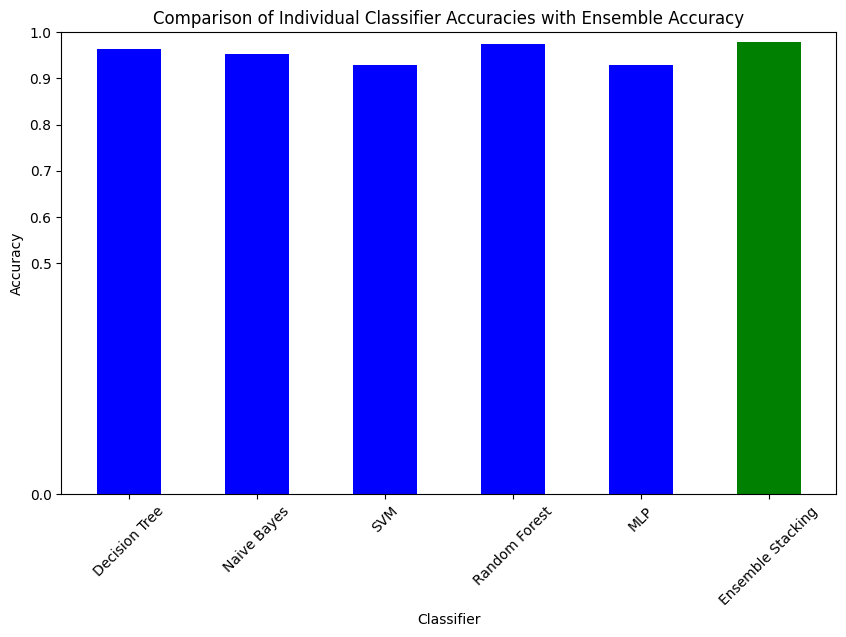

In [ ]:
import matplotlib.pyplot as plt

# Plotting individual accuracies vs ensemble accuracy
labels = ['Decision Tree', 'Naive Bayes', 'SVM', 'Random Forest', 'MLP', 'Ensemble Stacking']
accuracies = [dt_accuracy, nb_accuracy, svm_accuracy, rf_accuracy, mlp_accuracy, stack_model_test_accuracy]

plt.figure(figsize=(10, 6))
bar_width = 0.5  # Adjust the width of bars
bar_positions = range(len(labels))

plt.bar(bar_positions, accuracies, color=['b', 'b', 'b', 'b', 'b', 'g'], width=bar_width)
plt.xlabel('Classifier')
plt.ylabel('Accuracy')
plt.title('Comparison of Individual Classifier Accuracies with Ensemble Accuracy')
plt.xticks(bar_positions, labels, rotation=45)  # Rotate labels for better readability
plt.yticks([0, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0])  # Adjust y-axis ticks spacing
plt.ylim(0, 1)  # Set y-axis limit to ensure proper visualization
plt.show()


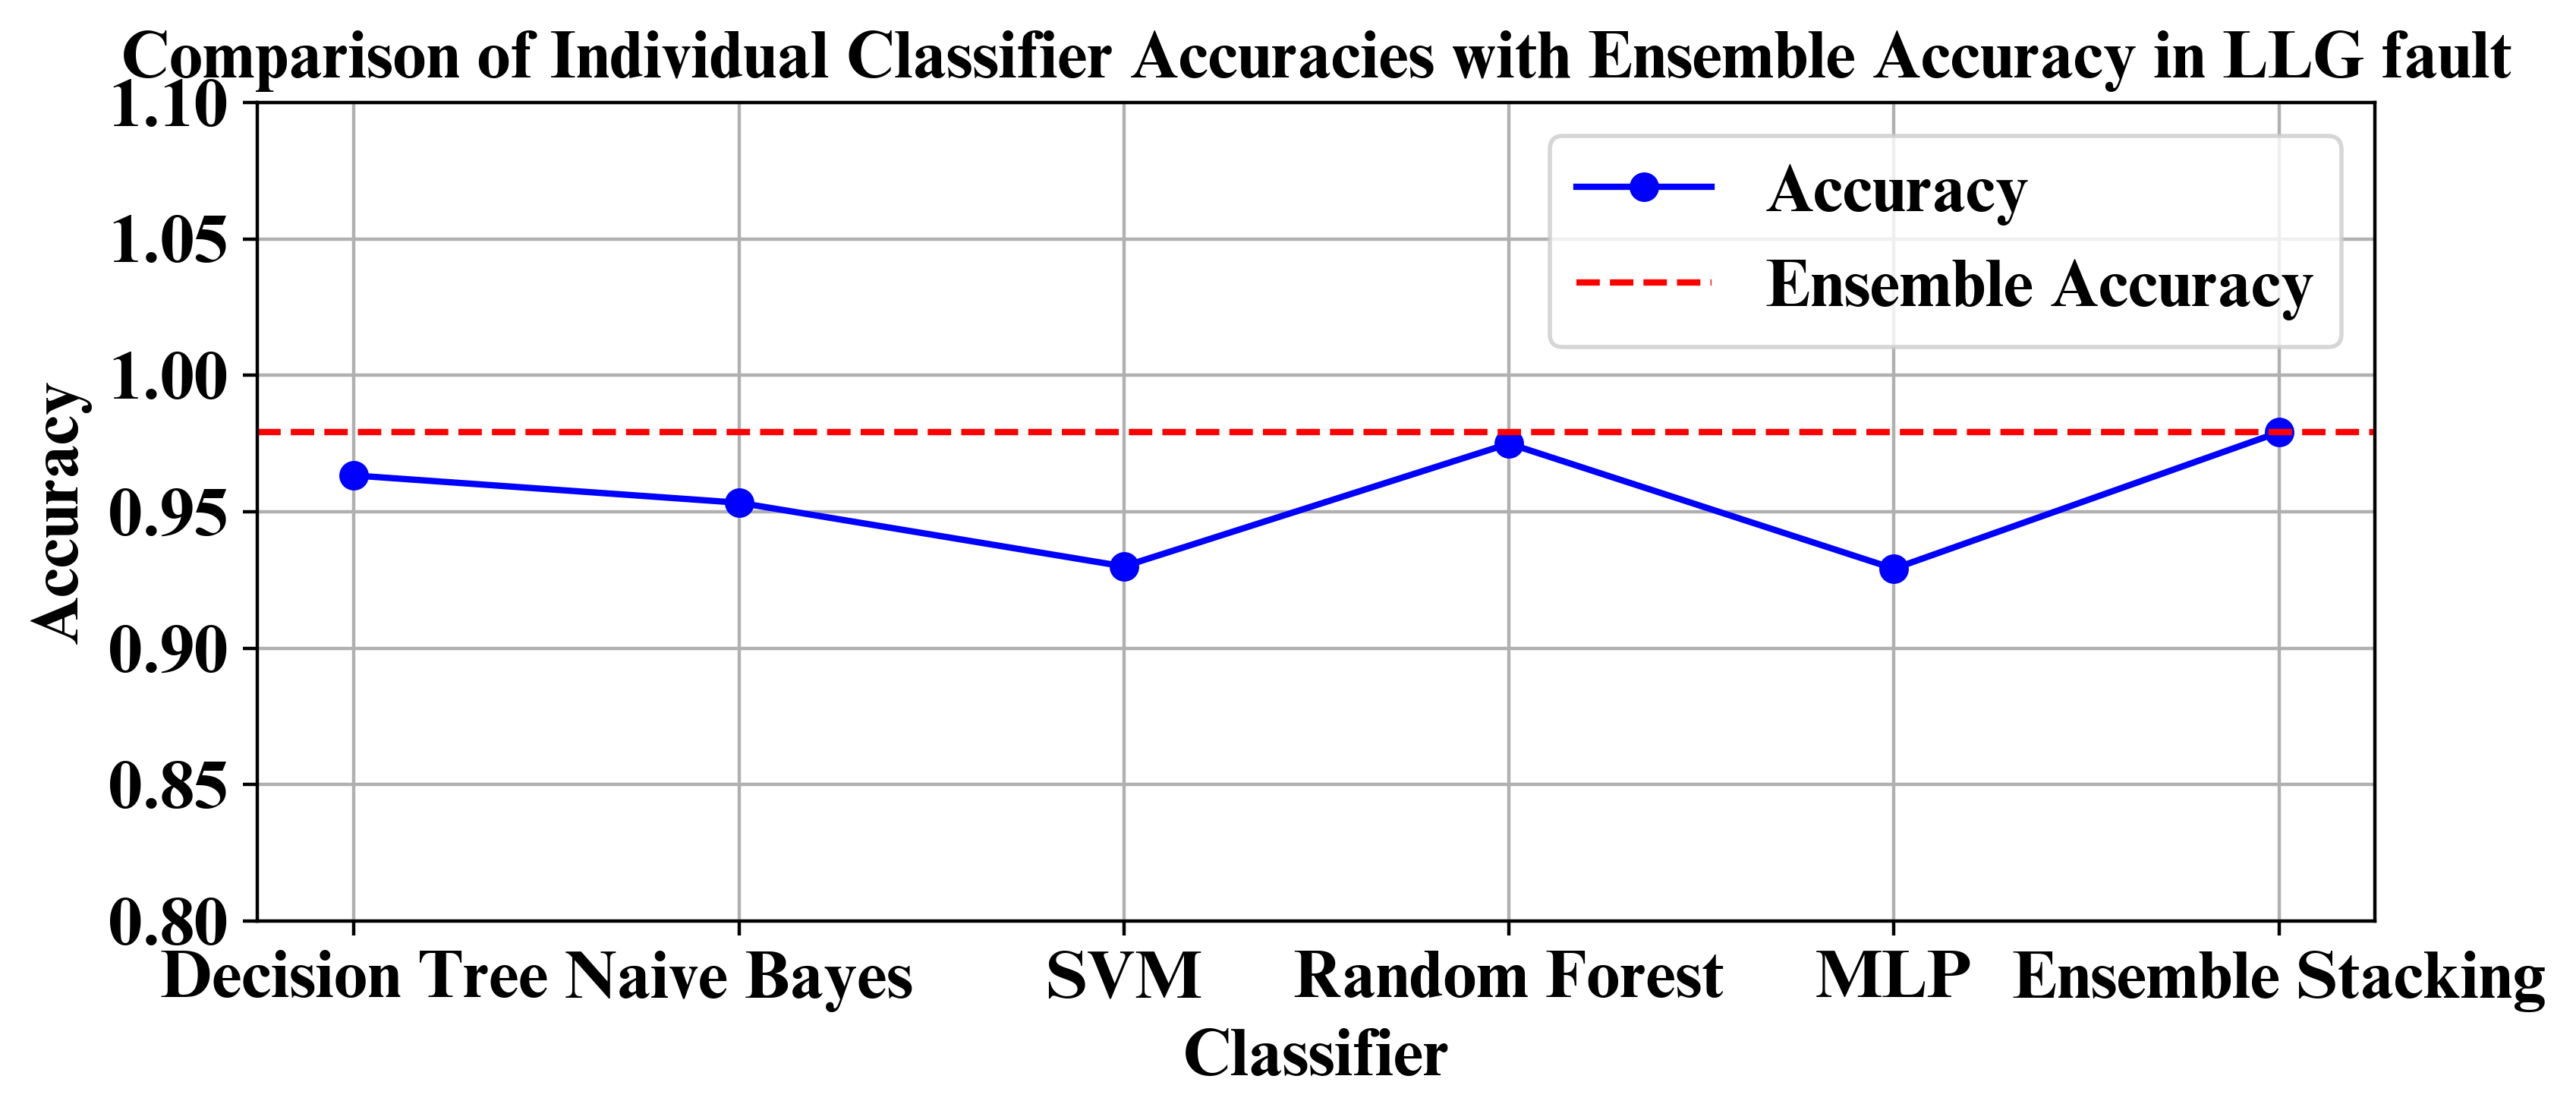

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)
custom_font.set_size(16)

plt.figure(figsize=(9, 3.5), dpi=400)
plt.plot(labels, accuracies, marker='o', color='b', label='Accuracy')
plt.axhline(y=stack_model_test_accuracy, color='r', linestyle='--', label='Ensemble Accuracy')

# Setting font properties for title, axis labels, and legend
plt.xlabel('Classifier', fontproperties=custom_font)
plt.ylabel('Accuracy', fontproperties=custom_font)
plt.title('Comparison of Individual Classifier Accuracies with Ensemble Accuracy in LLG fault', fontproperties=custom_font)

# Getting current axes and setting font properties for both x and y ticks
ax = plt.gca()
ax.tick_params(axis='x', labelsize=10)  # Adjust font size as needed
ax.tick_params(axis='y', labelsize=10)  # Adjust font size as needed
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontproperties(custom_font)

# Setting font properties for legend
plt.legend(prop=custom_font)
plt.xticks(fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
plt.ylim(0.8, 1.1)  # Set y-axis limit to ensure proper visualization
plt.grid(True)

# Saving the plot with custom font
plt.savefig('plot.png', dpi=400, bbox_inches='tight', pad_inches=0.1)
plt.show()


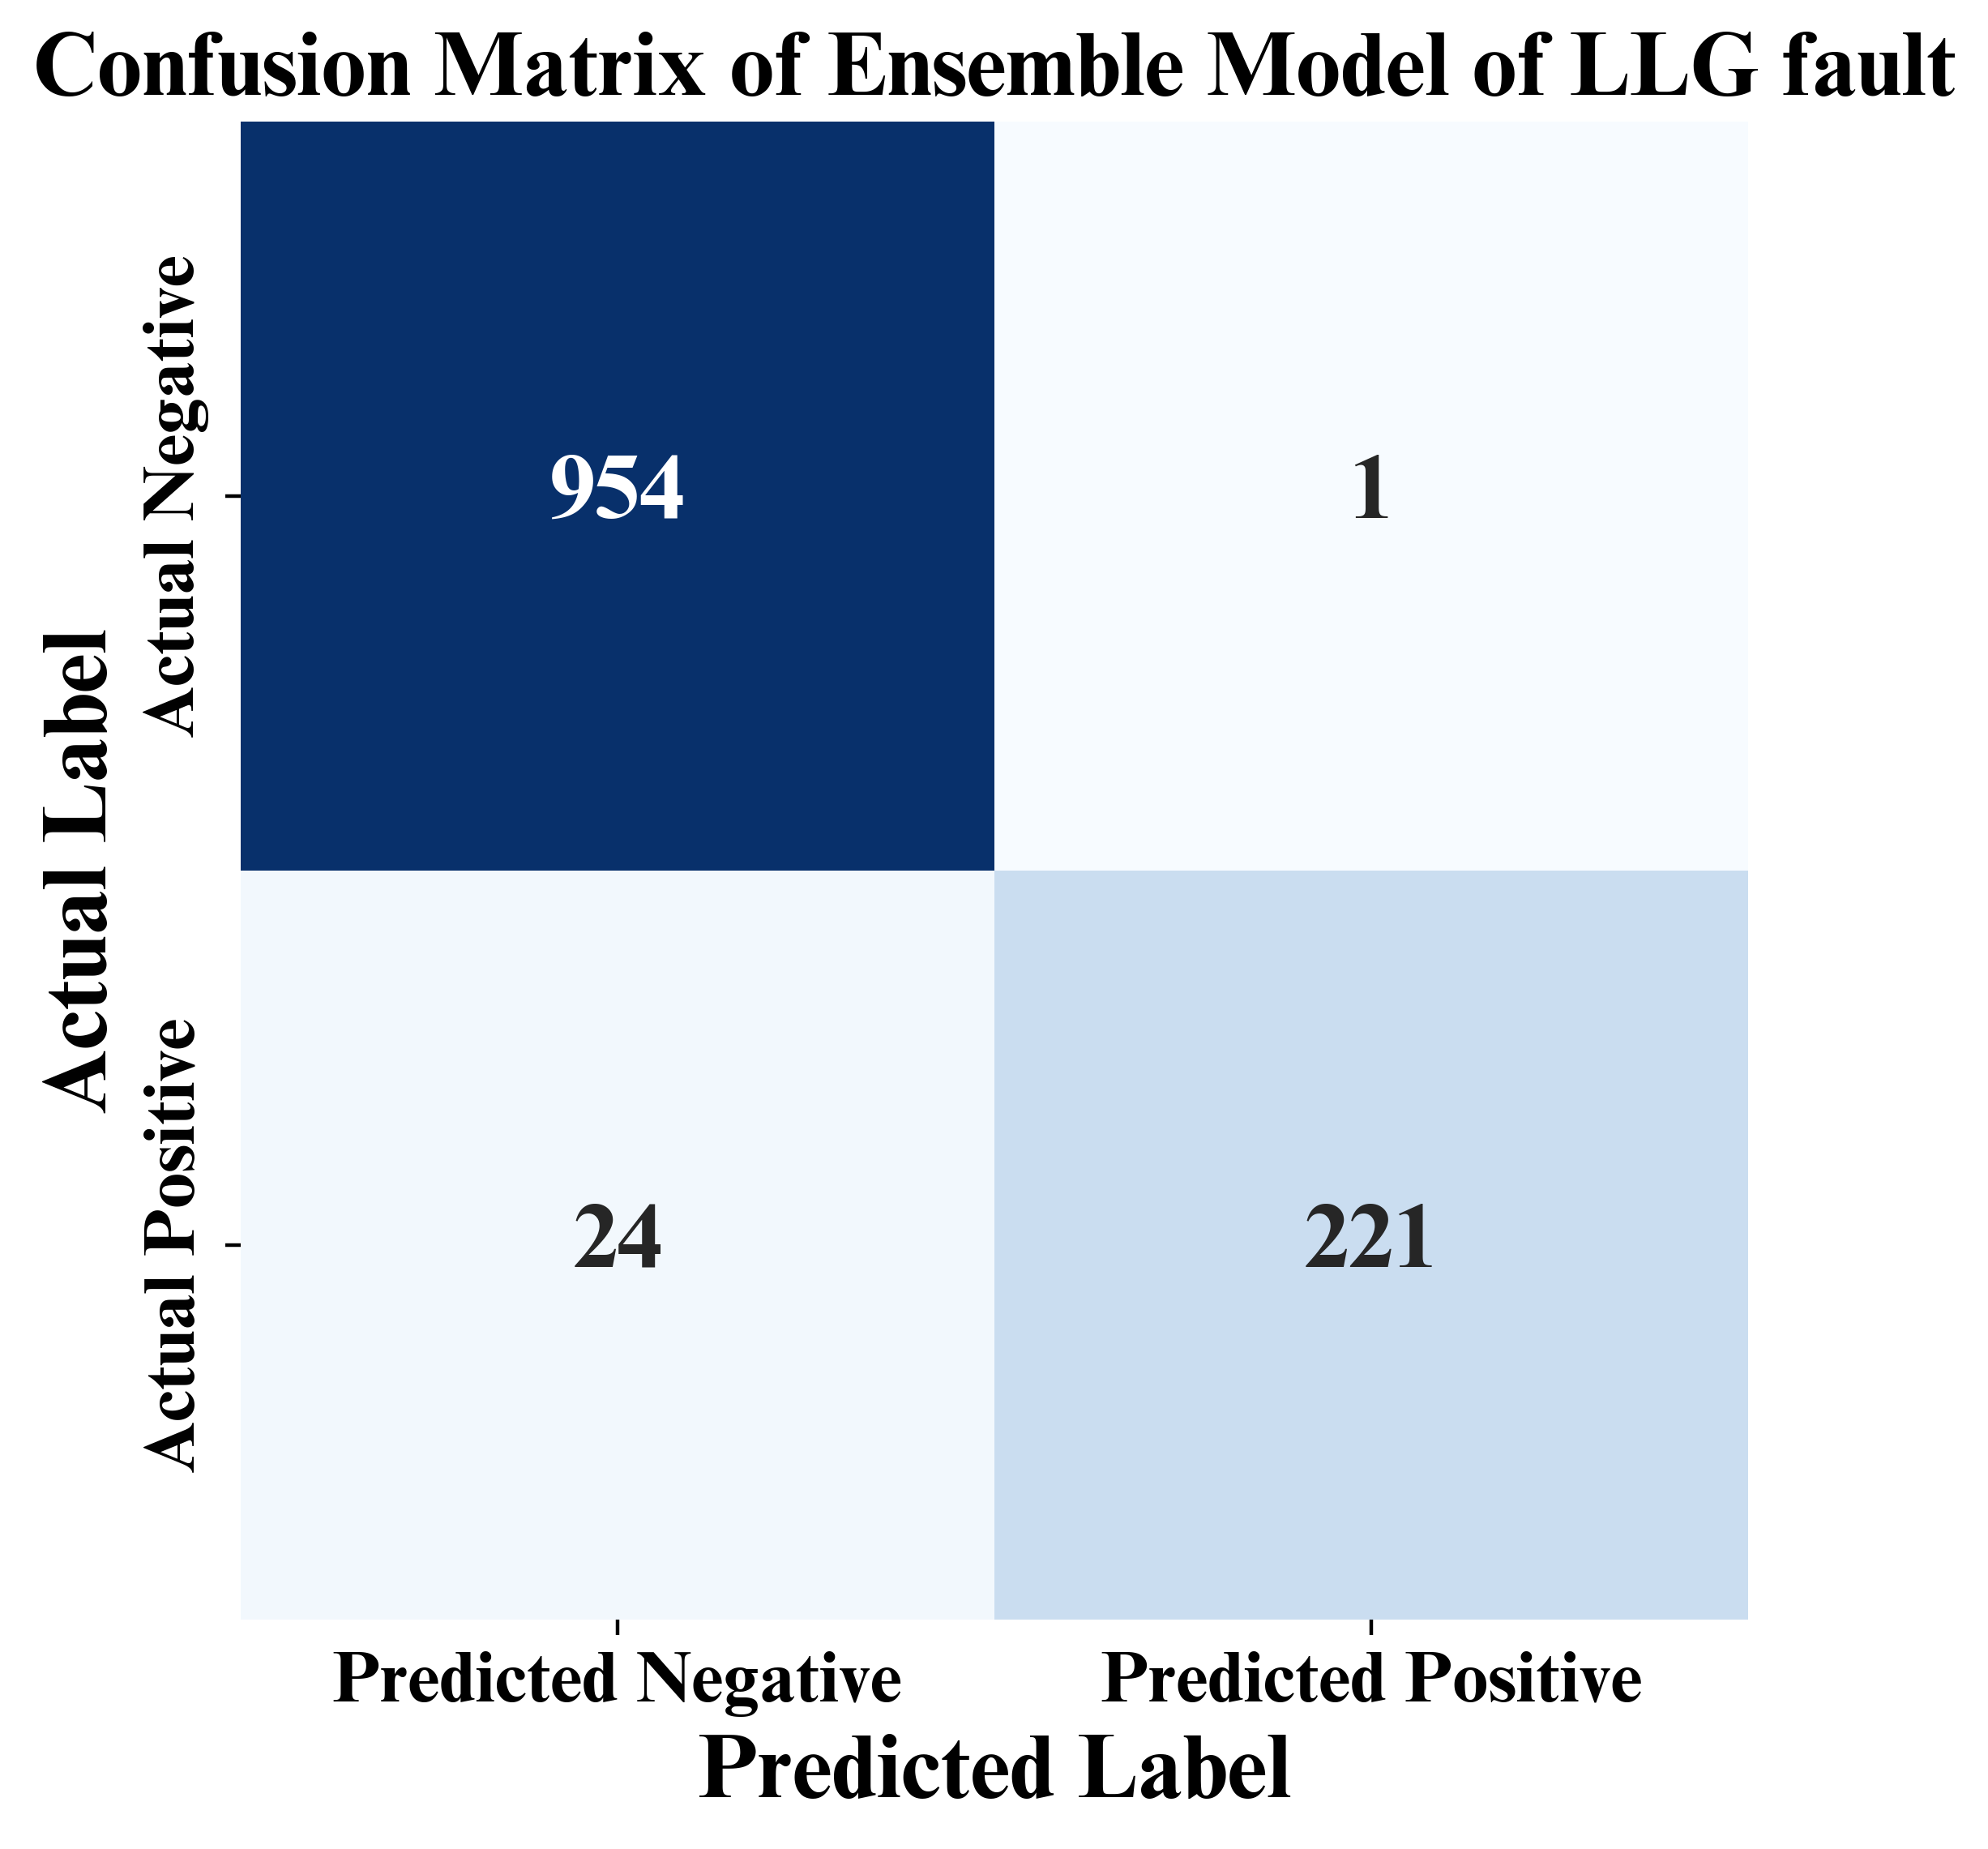

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties
import numpy as np

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)
custom_font.set_size(20)
# Generate the confusion matrix for the ensemble model
ensemble_conf_matrix = np.array([[954,   1],[ 24, 221]])

# Plot the heatmap
plt.figure(figsize=(6, 6), dpi=400)
heatmap = sns.heatmap(ensemble_conf_matrix, annot=True, fmt='d', cmap='Blues', cbar=False,
                      xticklabels=['Predicted Negative', 'Predicted Positive'],
                      yticklabels=['Actual Negative', 'Actual Positive'])

# Setting font properties for tick labels
for label in heatmap.get_xticklabels() + heatmap.get_yticklabels():
    label.set_fontproperties(custom_font)

# Set font properties for labels and title
plt.xlabel('Predicted Label', fontproperties=custom_font, fontsize=20)
plt.ylabel('Actual Label', fontproperties=custom_font, fontsize=20)
plt.title('Confusion Matrix of Ensemble Model of LLG fault', fontproperties=custom_font, fontsize=20)
plt.xticks(fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
# Set font properties for annotations
for text in heatmap.texts:
    text.set_fontproperties(custom_font)

plt.savefig('plot.png', dpi=400)
plt.show()


## Time

In [ ]:
# 1. Use the stacking model to predict faults on the dataset
stacking_pred = stacking_classifier.predict(X)

# 2. Identify the instances where the stacking model predicts a fault
predicted_fault_indices = np.where(stacking_pred == 1)[0]

# 3. Retrieve the timestamps (time instances) for these predicted fault instances
predicted_fault_times = df.iloc[predicted_fault_indices]['Time']

# Print the predicted fault times
print("Predicted Fault Times:")
print(predicted_fault_times)

Predicted Fault Times:
1201    0.200159
1202    0.200325
1203    0.200492
1205    0.200825
1206    0.200992
          ...   
2399    0.399817
2400    0.399984
2401    0.400151
2436    0.405984
2517    0.419483
Name: Time, Length: 1166, dtype: float64


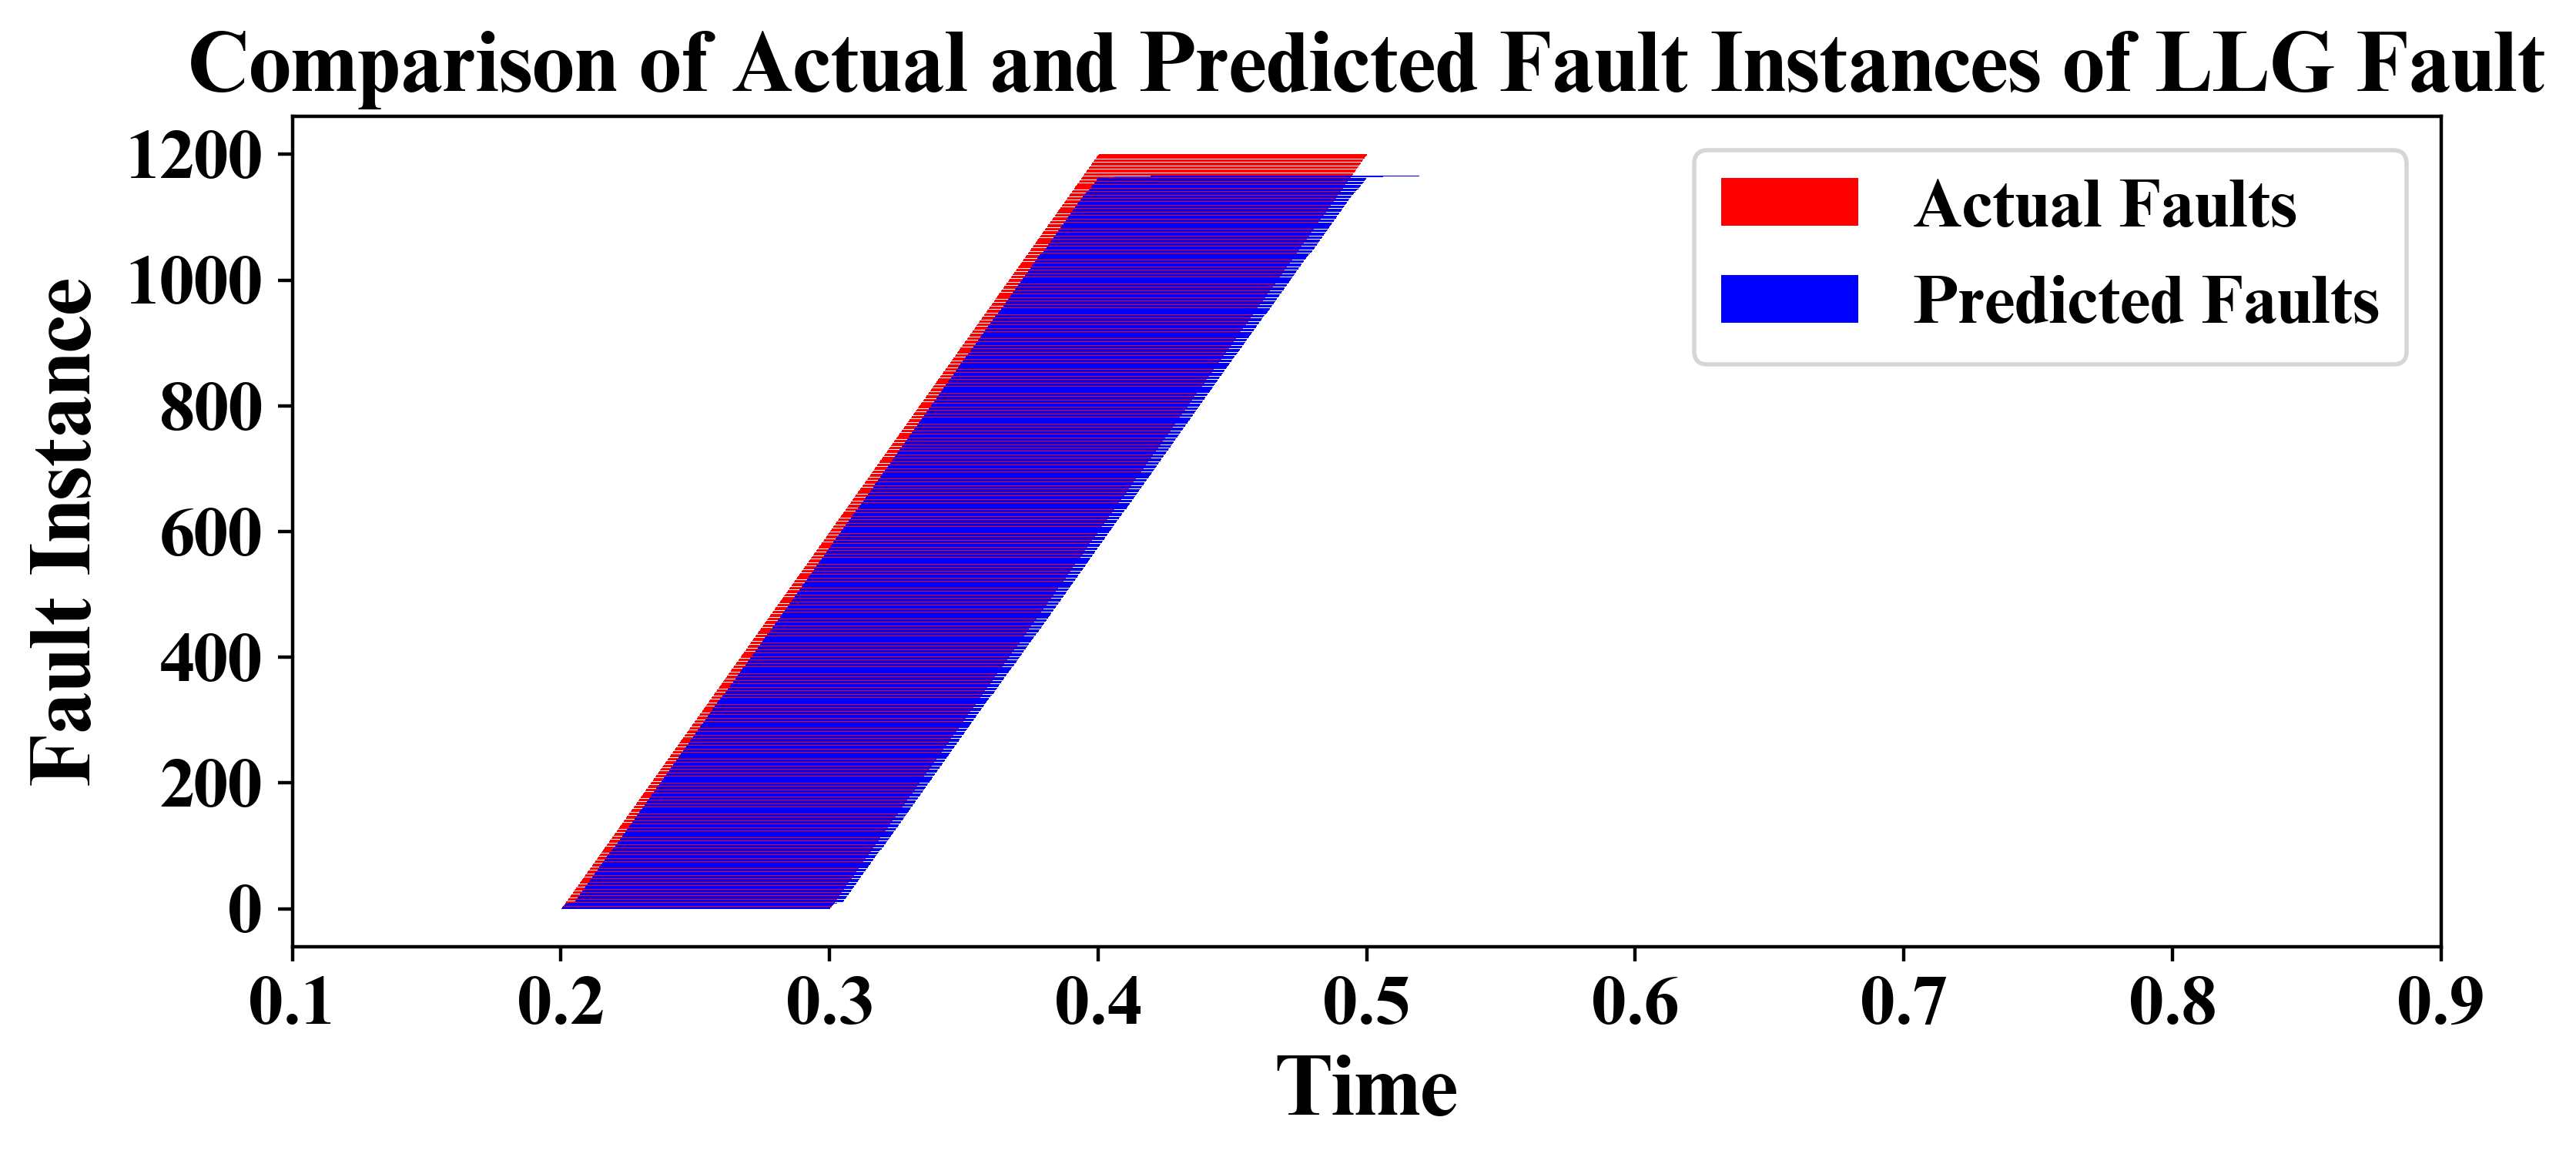

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path)
custom_font.set_size(16)

# Extract the time instances of actual faults
actual_fault_times = df[df['Fault'] == 1]['Time']

# Extract the time instances of predicted faults
predicted_fault_times = df.iloc[predicted_fault_indices]['Time']

# Create a timeline-like plot
plt.figure(figsize=(9, 3.5), dpi=400)

# Plot the actual fault instances as red bars
plt.barh(y=range(len(actual_fault_times)), width=0.1, left=actual_fault_times, color='red', label='Actual Faults')

# Plot the predicted fault instances as blue bars
plt.barh(y=[i + 0.5 for i in range(len(predicted_fault_times))], width=0.1, left=predicted_fault_times, color='blue', label='Predicted Faults')
plt.legend(['Actual Faults', 'Predicted Faults'], fontsize=20)
# Add labels and legend with specified font style
plt.xlabel('Time', fontproperties=custom_font, fontsize=20)
plt.ylabel('Fault Instance', fontproperties=custom_font, fontsize=20)
plt.title('Comparison of Actual and Predicted Fault Instances of LLG Fault', fontproperties=custom_font, fontsize=20)
plt.legend(prop=custom_font, fontsize=20)

# Set font properties for tick labels
plt.xticks(fontproperties=custom_font, fontsize=16)
plt.yticks(fontproperties=custom_font, fontsize=16)
plt.xlim(0.1, 0.9)
plt.savefig('plot1.png', dpi=400)
plt.show()


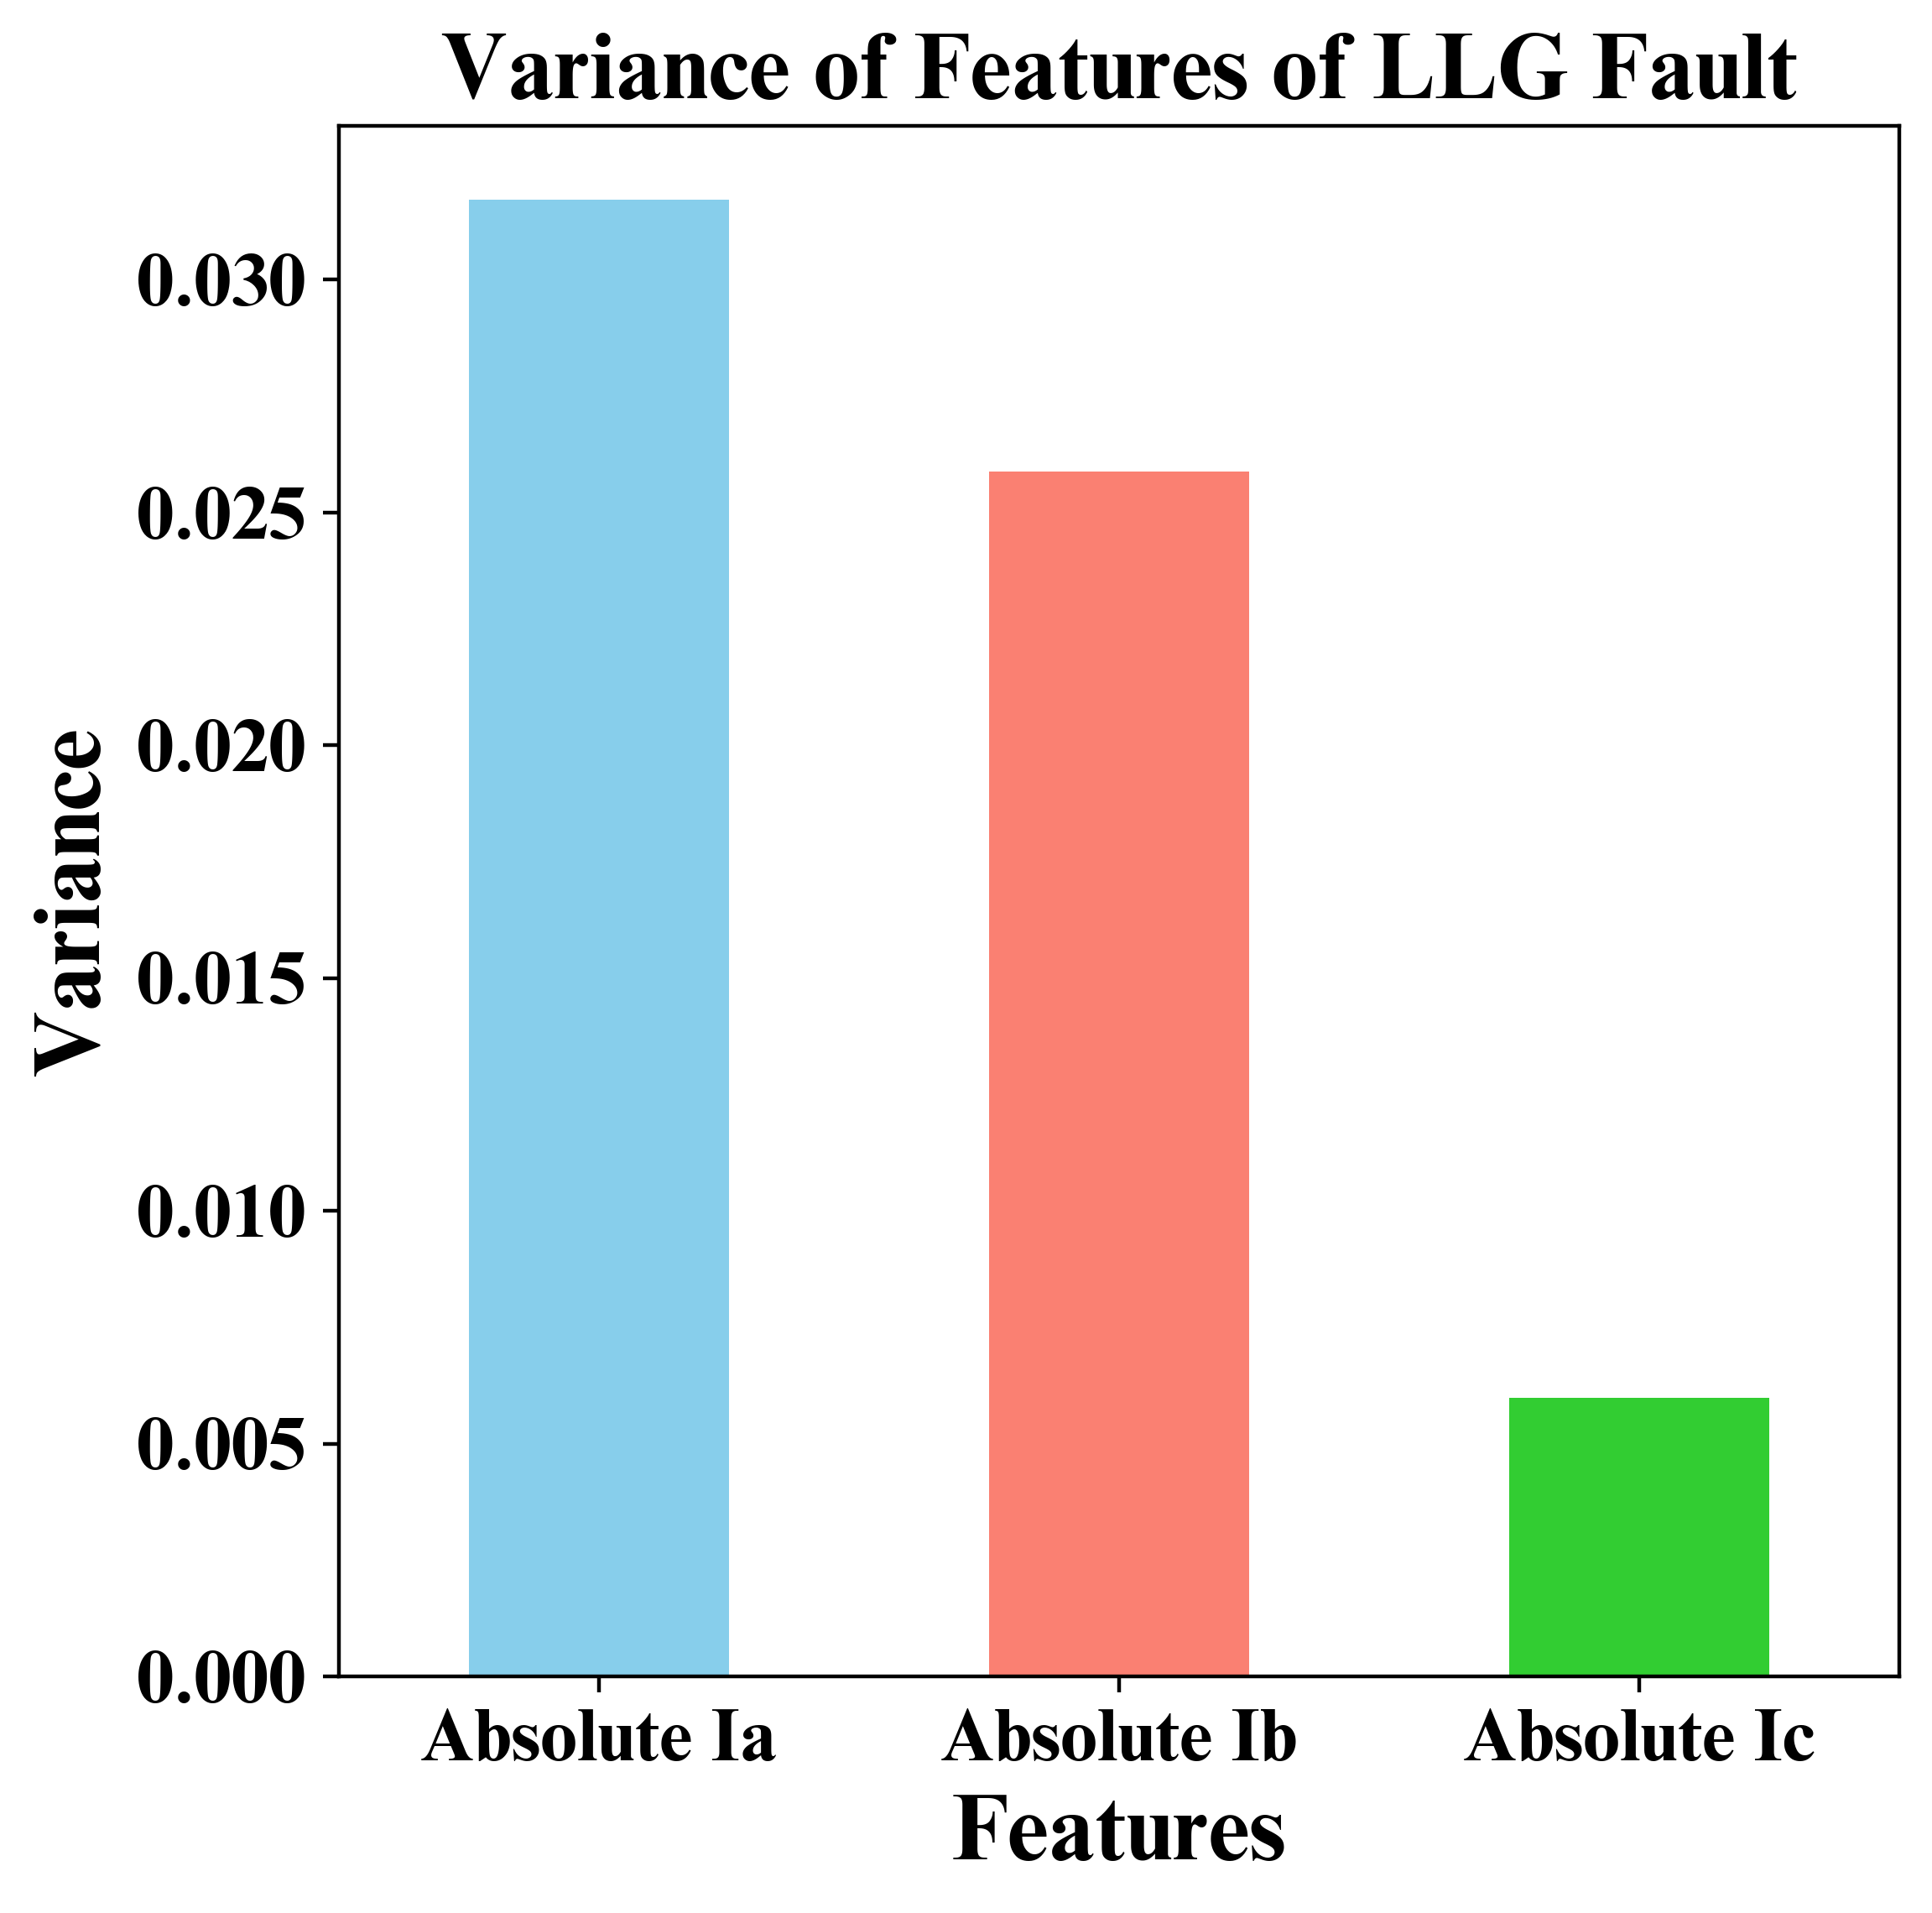

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.font_manager import FontProperties

font_path = '/content/drive/MyDrive/Fault_dataset/times new roman bold.ttf'
custom_font = FontProperties(fname=font_path, size=12)  # You can adjust the font size here

# Load your dataset (replace 'yoyour_dataset.csvur_dataset.csv' with your actual dataset)
df = pd.read_csv('/content/drive/MyDrive/Fault_dataset/ABG modified.csv')

# Select the features of interest
selected_features = ['Absolute Ia', 'Absolute Ib', 'Absolute Ic']

# Calculate the variance of each feature
variances = df[selected_features].var()

# Plot the variances in a bar graph with different colors
plt.figure(figsize=(6, 6), dpi=400)
colors = ['skyblue', 'salmon', 'limegreen']  # Define colors for each feature
variances.plot(kind='bar', color=colors)
plt.xlabel('Features', fontproperties=custom_font, fontsize=20)  # Adjust the font size here
plt.ylabel('Variance', fontproperties=custom_font, fontsize=20)  # Adjust the font size here
plt.title('Variance of Features of LLG Fault', fontproperties=custom_font, fontsize=20)  # Adjust the font size here
plt.xticks(rotation=0, fontproperties=custom_font, fontsize=16)  # Adjust the font size here
plt.yticks(fontproperties=custom_font, fontsize=16)  # Adjust the font size here

plt.savefig('plot1.png', dpi=400)
plt.show()
